# **Smart Logistics Intelligence Platform**

## Data Loading

In [8]:
import pandas as pd
import numpy as np

import matplotlib.pyplot as plt
import seaborn as sns

plt.style.use("ggplot")
%matplotlib inline

In [9]:
df = pd.read_csv("unclean_logistics_dataset.csv")

df.head()

,Order_ID,Distance_km,Vehicle_Type,Weather,Traffic,Driver_Rating,Shipping_Cost,Delivery_Time,Delay
0,1746,66.0,Bike,NaN,Low,4.0,1397.0,9.68,0
1,1866,22.0,Truck,Rain,Low,3.0,1172.0,11.01,0
2,1990,14.0,Truck,Fog,Medium,1.0,1119.0,2.64,0
3,1400,62.0,Van,Rain,Medium,5.0,10000.0,5.75,0
4,1976,72.0,Truck,Clear,Low,5.0,1405.0,4.89,0


##  Data Cleaning

In [10]:
print("Rows and Columns")

df.shape

Rows and Columns


(1030, 9)

In [11]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1030 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       1030 non-null   int64  
 1   Distance_km    988 non-null    float64
 2   Vehicle_Type   1030 non-null   object 
 3   Weather        988 non-null    object 
 4   Traffic        1030 non-null   object 
 5   Driver_Rating  988 non-null    float64
 6   Shipping_Cost  990 non-null    float64
 7   Delivery_Time  1030 non-null   float64
 8   Delay          1030 non-null   int64  
dtypes: float64(4), int64(2), object(3)
memory usage: 72.6+ KB


In [12]:
df.describe()

,Order_ID,Distance_km,Driver_Rating,Shipping_Cost,Delivery_Time,Delay
count,1030.000000,988.000000,988.000000,990.000000,1030.000000,1030.000000
mean,1500.135922,53.210526,3.052632,911.960606,6.743961,0.258252
std,289.365199,27.827305,1.417528,1003.518812,3.893803,0.437886
min,1001.000000,5.000000,1.000000,103.000000,1.010000,0.000000
25%,1248.250000,28.000000,2.000000,469.000000,3.842500,0.000000
50%,1501.000000,54.000000,3.000000,820.000000,6.400000,0.000000
75%,1750.750000,77.000000,4.000000,1179.250000,9.345000,1.000000
max,2000.000000,100.000000,5.000000,10000.000000,30.000000,1.000000


In [13]:
missing=df.isnull().sum()

missing

,0
Order_ID,0
Distance_km,42
Vehicle_Type,0
Weather,42
Traffic,0
Driver_Rating,42
Shipping_Cost,40
Delivery_Time,0
Delay,0


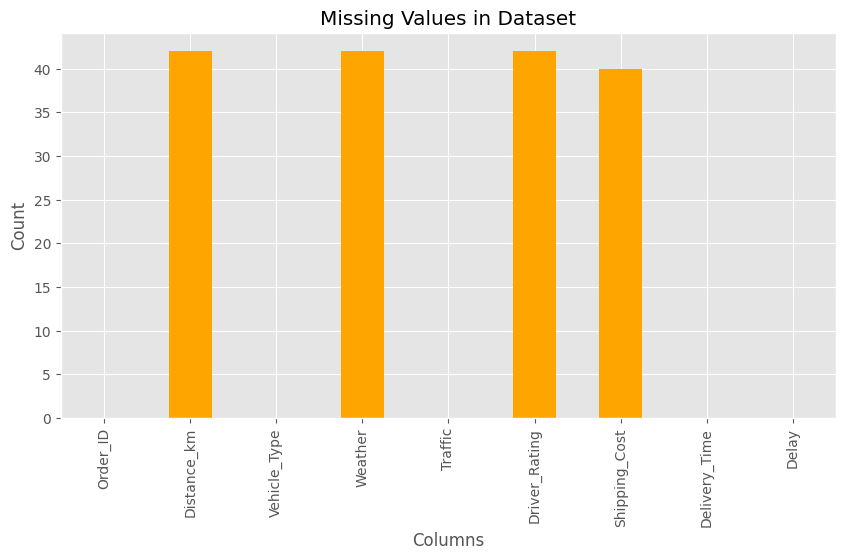

In [14]:
plt.figure(figsize=(10,5))

missing.plot(kind="bar",color="orange")

plt.title("Missing Values in Dataset")

plt.xlabel("Columns")

plt.ylabel("Count")

plt.show()

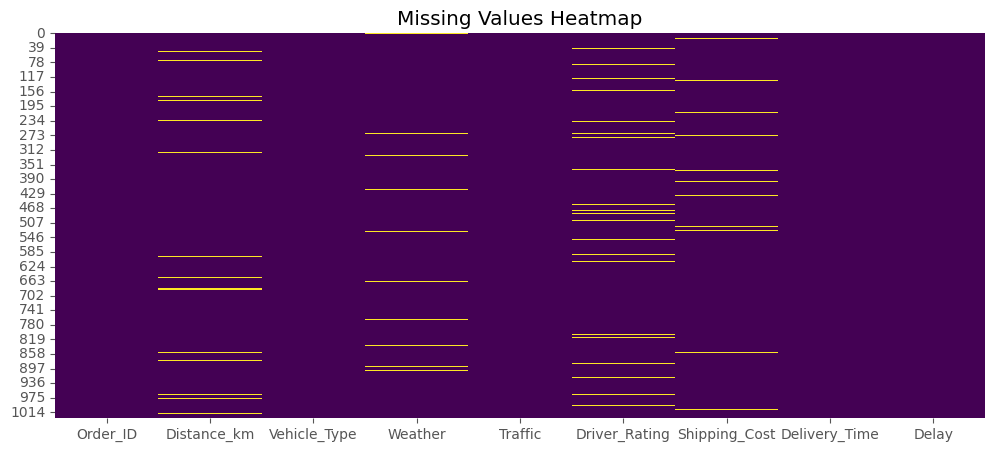

In [15]:
plt.figure(figsize=(12,5))

sns.heatmap(df.isnull(),
            cbar=False,
            cmap="viridis")

plt.title("Missing Values Heatmap")

plt.show()

In [16]:
print("Duplicate Rows :",df.duplicated().sum())

df=df.drop_duplicates()

print("New Shape :",df.shape)

Duplicate Rows : 22
New Shape : (1008, 9)


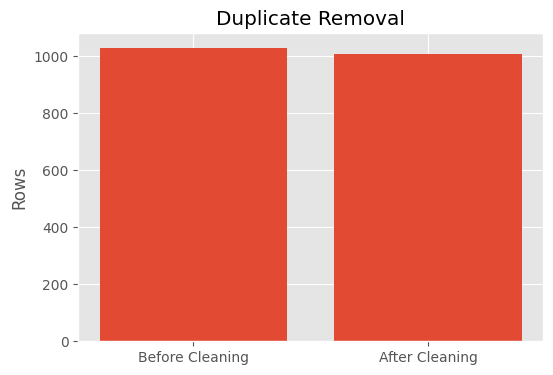

In [17]:
duplicate_before=1030
duplicate_after=df.shape[0]

plt.figure(figsize=(6,4))

plt.bar(["Before Cleaning","After Cleaning"],
        [duplicate_before,duplicate_after])

plt.title("Duplicate Removal")

plt.ylabel("Rows")

plt.show()

In [18]:
num_cols=[
    "Distance_km",
    "Driver_Rating",
    "Shipping_Cost"
]

for col in num_cols:
    df[col]=df[col].fillna(df[col].median())

In [19]:
df["Weather"]=df["Weather"].fillna(
    df["Weather"].mode()[0]
)

In [20]:
df.isnull().sum()

,0
Order_ID,0
Distance_km,0
Vehicle_Type,0
Weather,0
Traffic,0
Driver_Rating,0
Shipping_Cost,0
Delivery_Time,0
Delay,0


In [21]:
df["Vehicle_Type"]=df["Vehicle_Type"].replace({

    "bike":"Bike",

    "TRUCK":"Truck"

})

df["Weather"]=df["Weather"].replace({

    "rain":"Rain"

})

df["Traffic"]=df["Traffic"].replace({

    "high":"High"

})

In [22]:
print(df["Vehicle_Type"].unique())

print(df["Weather"].unique())

print(df["Traffic"].unique())

['Bike' 'Truck' 'Van']
['Fog' 'Rain' 'Clear' 'Cloudy']
['Low' 'Medium' 'High']


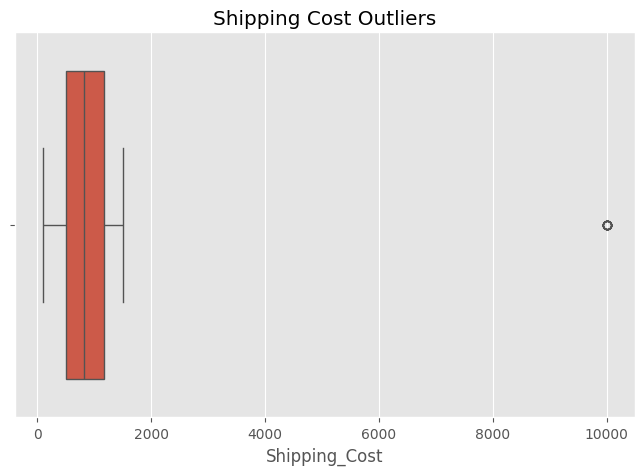

In [23]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Shipping_Cost"])

plt.title("Shipping Cost Outliers")

plt.show()

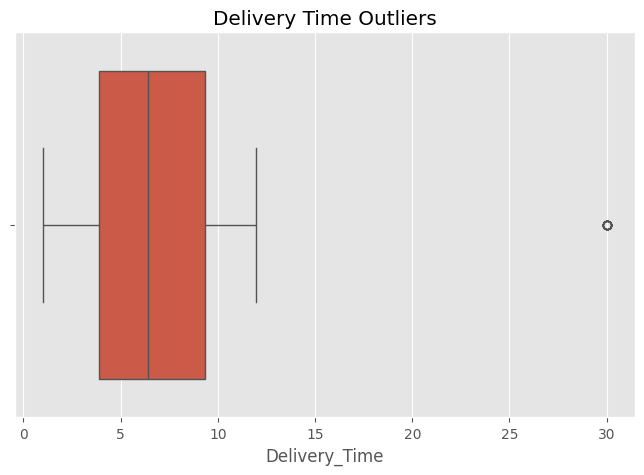

In [24]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Delivery_Time"])

plt.title("Delivery Time Outliers")

plt.show()

In [25]:
Q1=df["Shipping_Cost"].quantile(.25)

Q3=df["Shipping_Cost"].quantile(.75)

IQR=Q3-Q1

lower=Q1-1.5*IQR

upper=Q3+1.5*IQR

df=df[(df["Shipping_Cost"]>=lower)&
      (df["Shipping_Cost"]<=upper)]

In [26]:
Q1=df["Delivery_Time"].quantile(.25)

Q3=df["Delivery_Time"].quantile(.75)

IQR=Q3-Q1

lower=Q1-1.5*IQR

upper=Q3+1.5*IQR

df=df[(df["Delivery_Time"]>=lower)&
      (df["Delivery_Time"]<=upper)]

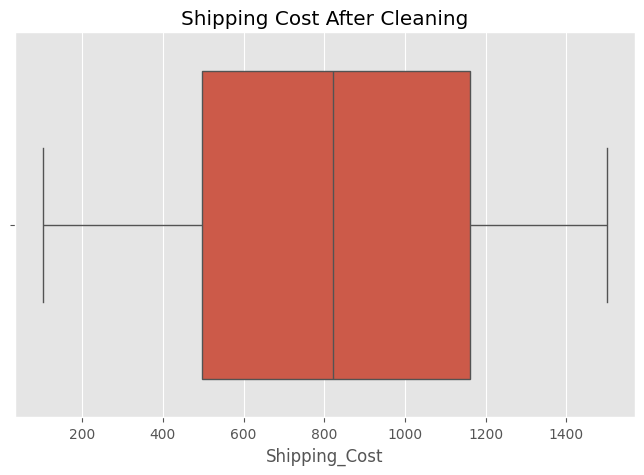

In [27]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Shipping_Cost"])

plt.title("Shipping Cost After Cleaning")

plt.show()

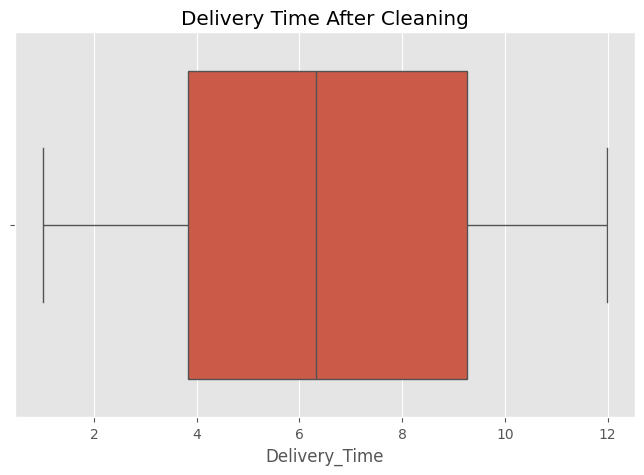

In [28]:
plt.figure(figsize=(8,5))

sns.boxplot(x=df["Delivery_Time"])

plt.title("Delivery Time After Cleaning")

plt.show()

In [29]:
df.info()

<class 'pandas.core.frame.DataFrame'>
Index: 988 entries, 0 to 1029
Data columns (total 9 columns):
 #   Column         Non-Null Count  Dtype  
---  ------         --------------  -----  
 0   Order_ID       988 non-null    int64  
 1   Distance_km    988 non-null    float64
 2   Vehicle_Type   988 non-null    object 
 3   Weather        988 non-null    object 
 4   Traffic        988 non-null    object 
 5   Driver_Rating  988 non-null    float64
 6   Shipping_Cost  988 non-null    float64
 7   Delivery_Time  988 non-null    float64
 8   Delay          988 non-null    int64  
dtypes: float64(4), int64(2), object(3)
memory usage: 77.2+ KB


In [30]:
df.to_csv("cleaned_logistics_dataset.csv",
          index=False)

print("Dataset Saved Successfully")

Dataset Saved Successfully


##  Exploratory Data Analysis

In [31]:
df = pd.read_csv("cleaned_logistics_dataset.csv")

df.head()

,Order_ID,Distance_km,Vehicle_Type,Weather,Traffic,Driver_Rating,Shipping_Cost,Delivery_Time,Delay
0,1746,66.0,Bike,Fog,Low,4.0,1397.0,9.68,0
1,1866,22.0,Truck,Rain,Low,3.0,1172.0,11.01,0
2,1990,14.0,Truck,Fog,Medium,1.0,1119.0,2.64,0
3,1976,72.0,Truck,Clear,Low,5.0,1405.0,4.89,0
4,1991,86.0,Bike,Clear,High,4.0,645.0,2.67,0


In [32]:
print("Dataset Shape:", df.shape)

Dataset Shape: (988, 9)


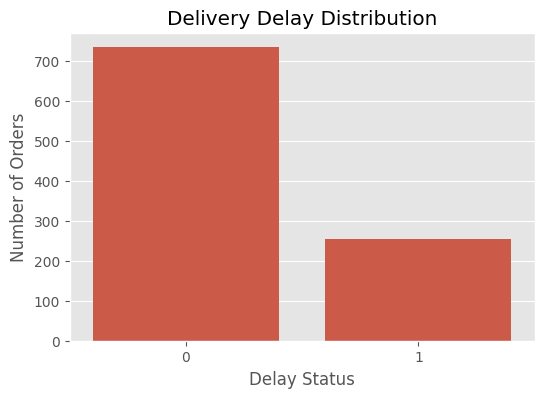

In [33]:
plt.figure(figsize=(6,4))

sns.countplot(x="Delay", data=df)

plt.title("Delivery Delay Distribution")
plt.xlabel("Delay Status")
plt.ylabel("Number of Orders")

plt.show()

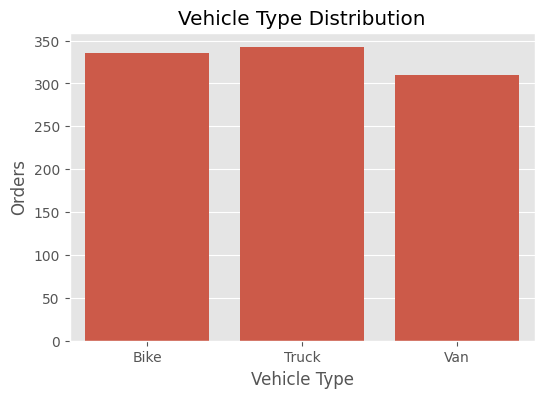

In [34]:
plt.figure(figsize=(6,4))

sns.countplot(x="Vehicle_Type", data=df)

plt.title("Vehicle Type Distribution")
plt.xlabel("Vehicle Type")
plt.ylabel("Orders")

plt.show()

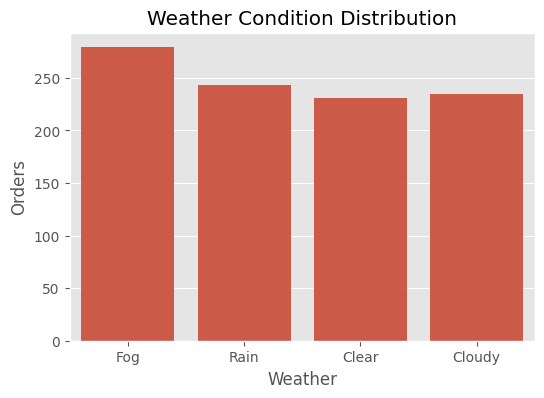

In [35]:
plt.figure(figsize=(6,4))

sns.countplot(x="Weather", data=df)

plt.title("Weather Condition Distribution")
plt.xlabel("Weather")
plt.ylabel("Orders")

plt.show()

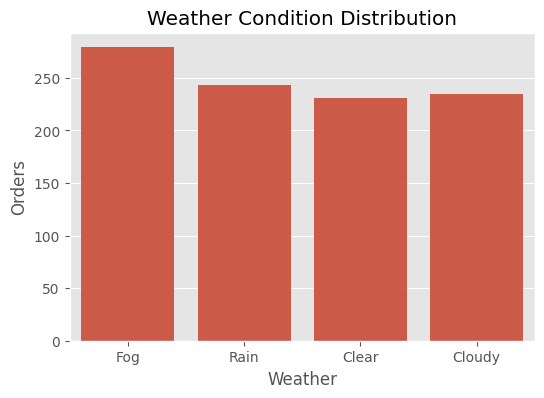

In [36]:
plt.figure(figsize=(6,4))

sns.countplot(x="Weather", data=df)

plt.title("Weather Condition Distribution")
plt.xlabel("Weather")
plt.ylabel("Orders")

plt.show()

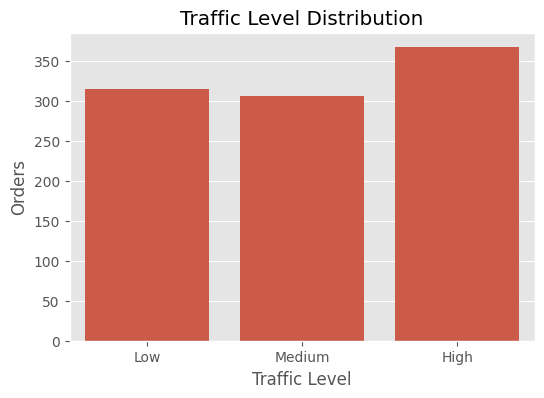

In [37]:
plt.figure(figsize=(6,4))

sns.countplot(x="Traffic", data=df)

plt.title("Traffic Level Distribution")
plt.xlabel("Traffic Level")
plt.ylabel("Orders")

plt.show()

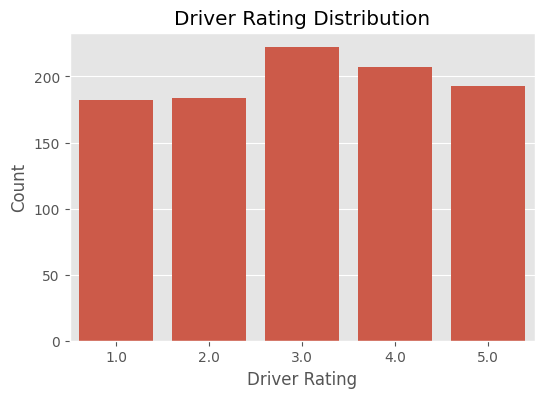

In [38]:
plt.figure(figsize=(6,4))

sns.countplot(x="Driver_Rating", data=df)

plt.title("Driver Rating Distribution")
plt.xlabel("Driver Rating")
plt.ylabel("Count")

plt.show()

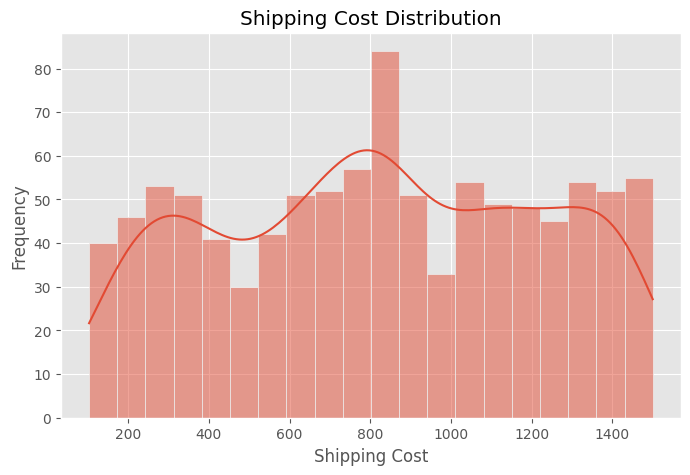

In [39]:
plt.figure(figsize=(8,5))

sns.histplot(df["Shipping_Cost"], bins=20, kde=True)

plt.title("Shipping Cost Distribution")
plt.xlabel("Shipping Cost")
plt.ylabel("Frequency")

plt.show()

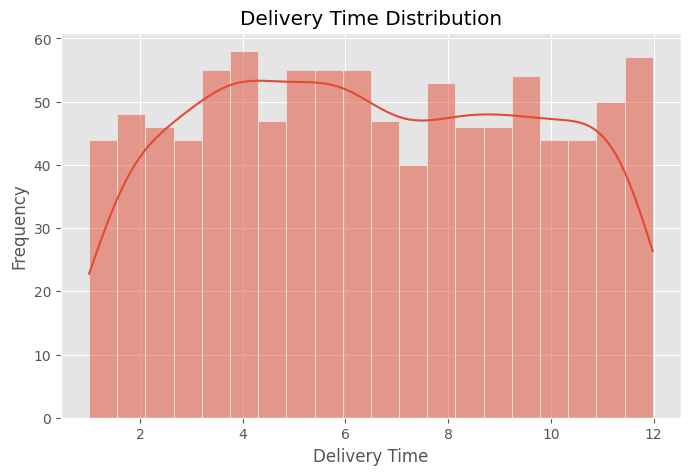

In [40]:
plt.figure(figsize=(8,5))

sns.histplot(df["Delivery_Time"], bins=20, kde=True)

plt.title("Delivery Time Distribution")
plt.xlabel("Delivery Time")
plt.ylabel("Frequency")

plt.show()

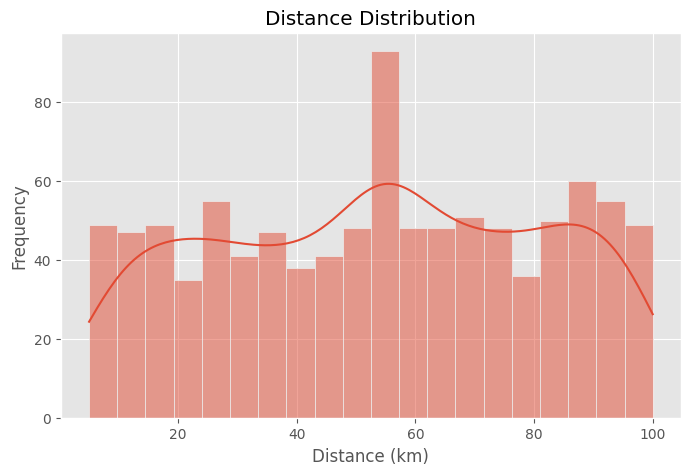

In [41]:
plt.figure(figsize=(8,5))

sns.histplot(df["Distance_km"], bins=20, kde=True)

plt.title("Distance Distribution")
plt.xlabel("Distance (km)")
plt.ylabel("Frequency")

plt.show()

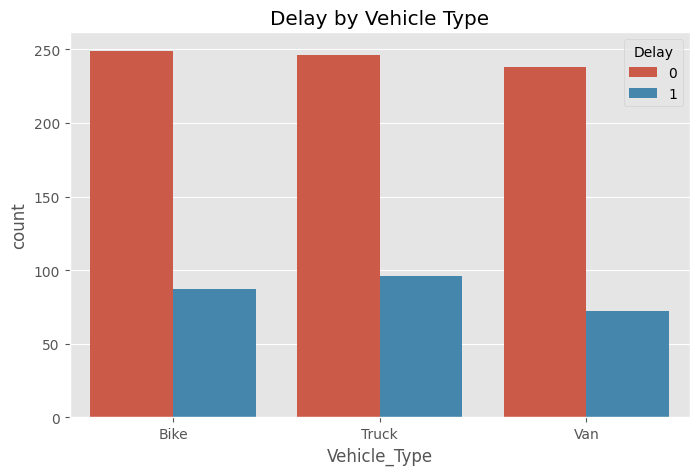

In [42]:
plt.figure(figsize=(8,5))

sns.countplot(x="Vehicle_Type",
              hue="Delay",
              data=df)

plt.title("Delay by Vehicle Type")

plt.show()

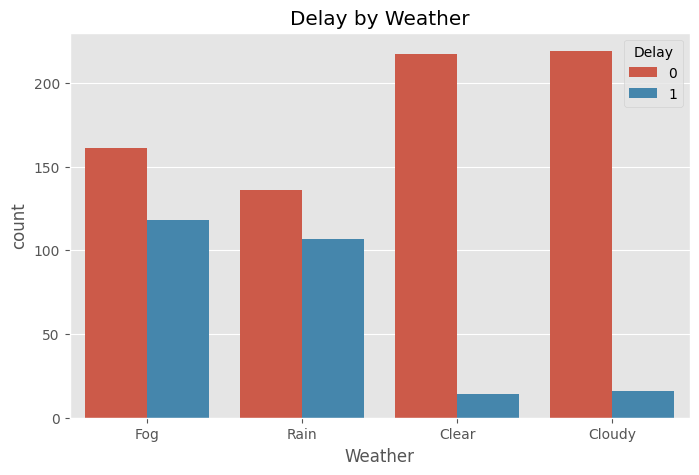

In [43]:
plt.figure(figsize=(8,5))

sns.countplot(x="Weather",
              hue="Delay",
              data=df)

plt.title("Delay by Weather")

plt.show()

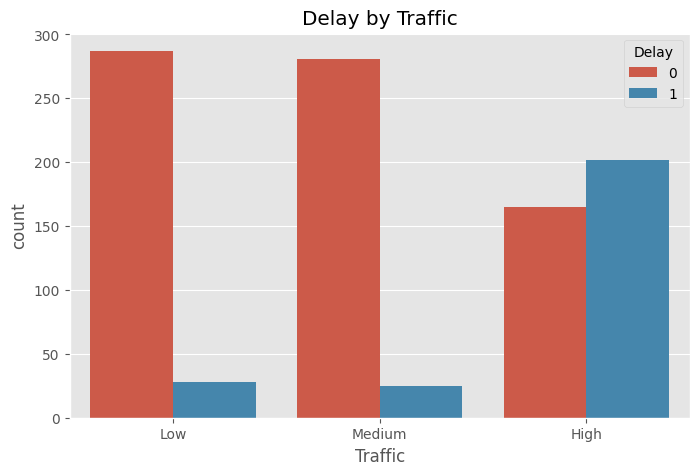

In [44]:
plt.figure(figsize=(8,5))

sns.countplot(x="Traffic",
              hue="Delay",
              data=df)

plt.title("Delay by Traffic")

plt.show()

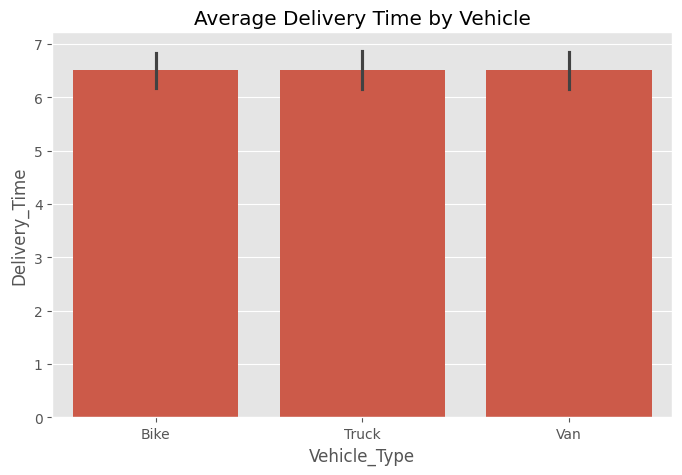

In [45]:
plt.figure(figsize=(8,5))

sns.barplot(x="Vehicle_Type",
            y="Delivery_Time",
            data=df)

plt.title("Average Delivery Time by Vehicle")

plt.show()

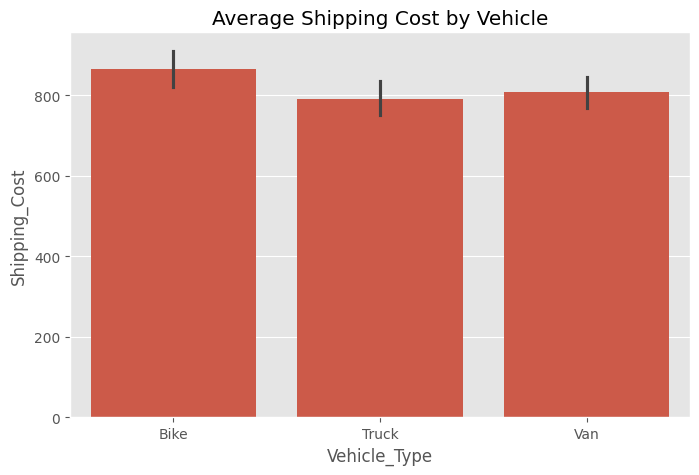

In [46]:
plt.figure(figsize=(8,5))

sns.barplot(x="Vehicle_Type",
            y="Shipping_Cost",
            data=df)

plt.title("Average Shipping Cost by Vehicle")

plt.show()

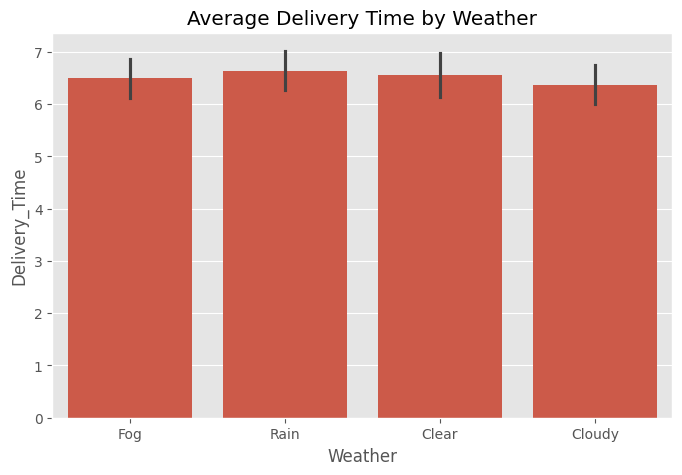

In [47]:
plt.figure(figsize=(8,5))

sns.barplot(x="Weather",
            y="Delivery_Time",
            data=df)

plt.title("Average Delivery Time by Weather")

plt.show()

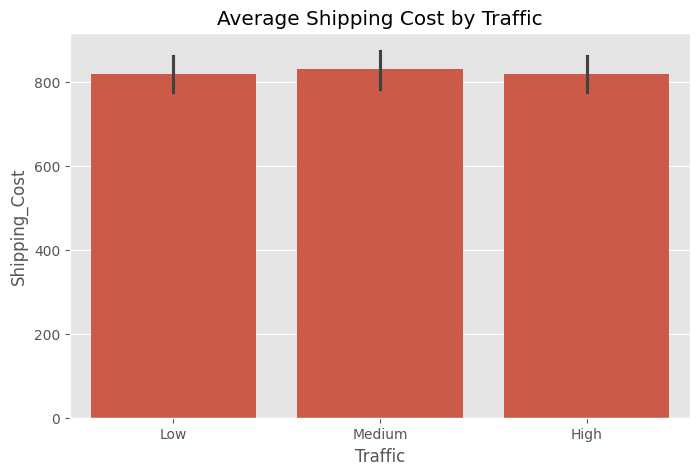

In [48]:
plt.figure(figsize=(8,5))

sns.barplot(x="Traffic",
            y="Shipping_Cost",
            data=df)

plt.title("Average Shipping Cost by Traffic")

plt.show()

In [49]:
from sklearn.preprocessing import LabelEncoder

temp = df.copy()

encoder = LabelEncoder()

for col in ["Vehicle_Type", "Weather", "Traffic"]:
    temp[col] = encoder.fit_transform(temp[col])

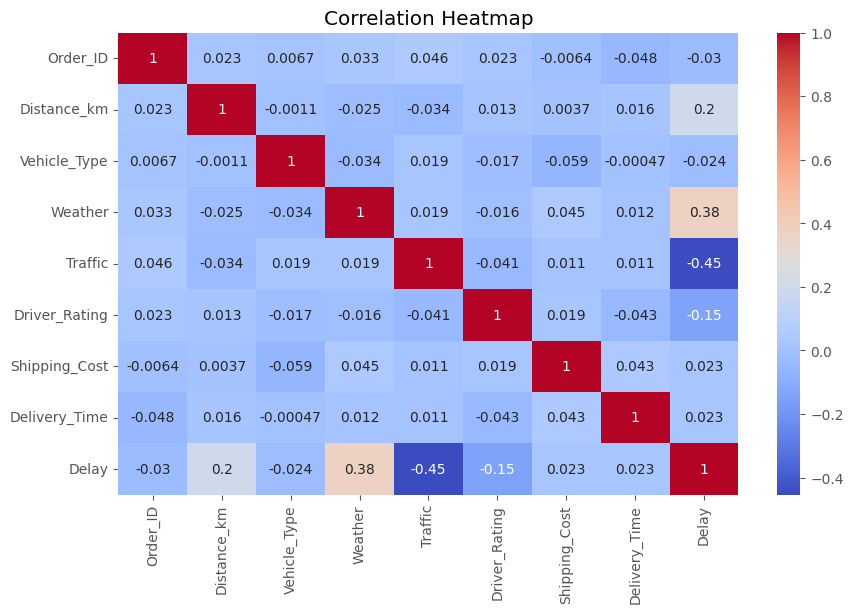

In [50]:
plt.figure(figsize=(10,6))

sns.heatmap(temp.corr(),
            annot=True,
            cmap="coolwarm")

plt.title("Correlation Heatmap")

plt.show()

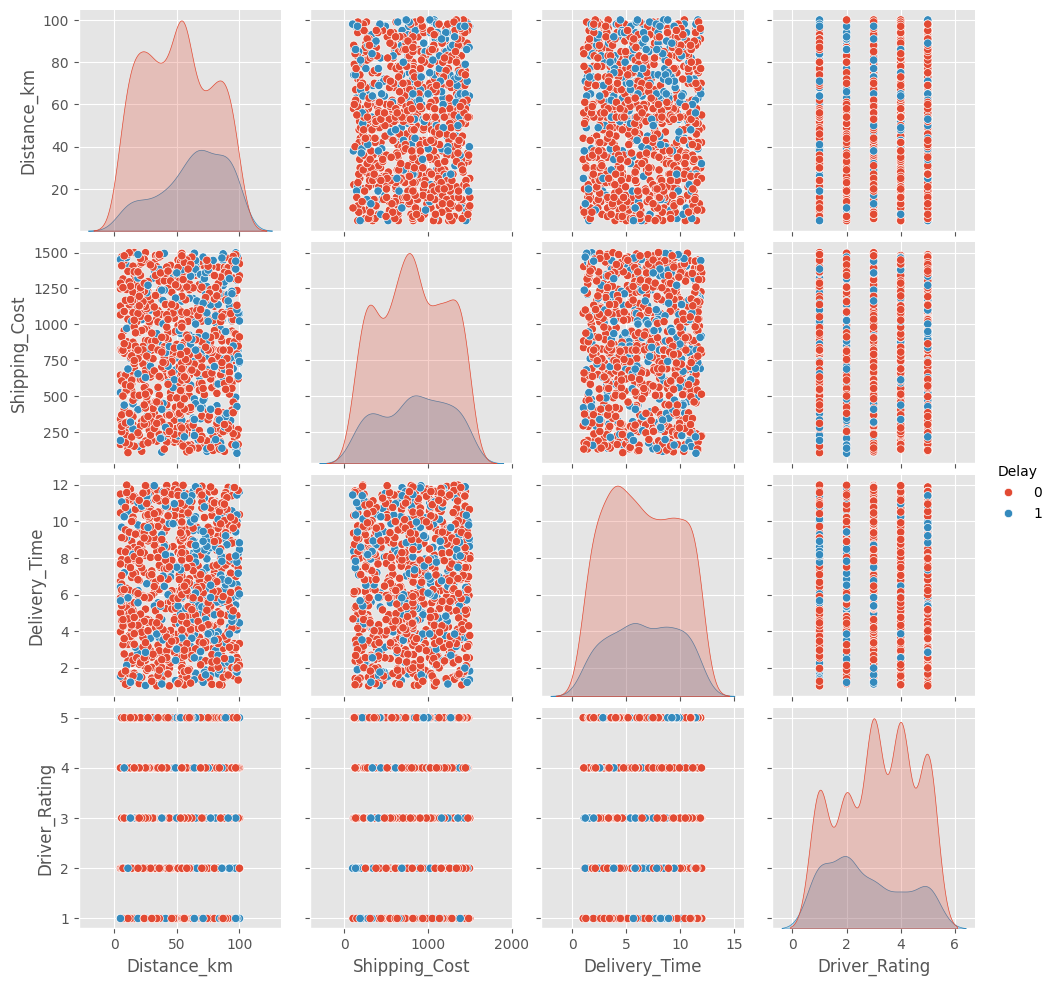

In [51]:
sns.pairplot(
    temp[
        [
            "Distance_km",
            "Shipping_Cost",
            "Delivery_Time",
            "Driver_Rating",
            "Delay"
        ]
    ],
    hue="Delay"
)

plt.show()

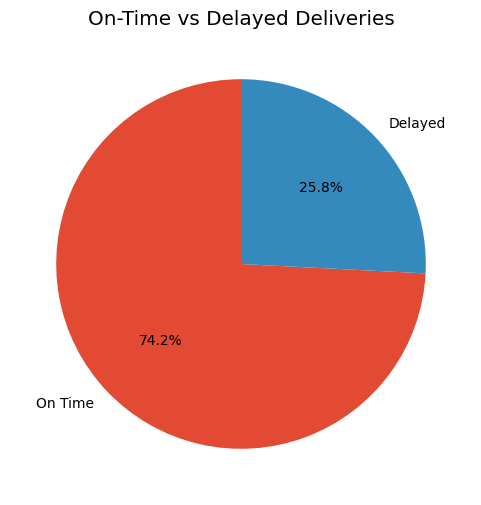

In [52]:
delay_counts = df["Delay"].value_counts()

plt.figure(figsize=(6,6))

plt.pie(delay_counts,
        labels=["On Time","Delayed"],
        autopct="%1.1f%%",
        startangle=90)

plt.title("On-Time vs Delayed Deliveries")

plt.show()

In [53]:
df.to_csv("EDA_Logistics_Dataset.csv", index=False)

print("EDA Completed Successfully")

EDA Completed Successfully


# Delivery Delay Prediction

In [88]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestClassifier

from sklearn.metrics import accuracy_score
from sklearn.metrics import confusion_matrix
from sklearn.metrics import classification_report

import seaborn as sns
import matplotlib.pyplot as plt

In [89]:
# Create Delay column
df["Delay"] = (df["Delivery_Time"] > df["Delivery_Time"].median()).astype(int)

df["Delay"].value_counts()

,count
Delay,
1,494
0,494


In [90]:
features = [

    "Distance_km",

    "Shipping_Cost",

    "Driver_Rating"

]

X = df[features]

y = df["Delay"]

In [91]:
X_train, X_test, y_train, y_test = train_test_split(

    X,

    y,

    test_size=0.2,

    random_state=42

)

In [92]:
delay_model = RandomForestClassifier(

    n_estimators=100,

    random_state=42

)

delay_model.fit(X_train, y_train)

RandomForestClassifier(random_state=42)

In [93]:
delay_prediction = delay_model.predict(X_test)

In [94]:
accuracy = accuracy_score(y_test, delay_prediction)

print("Accuracy :", round(accuracy*100,2), "%")

Accuracy : 43.94 %


In [95]:
print(classification_report(y_test, delay_prediction))

              precision    recall  f1-score   support

           0       0.50      0.49      0.49       111
           1       0.37      0.38      0.37        87

    accuracy                           0.44       198
   macro avg       0.43      0.43      0.43       198
weighted avg       0.44      0.44      0.44       198



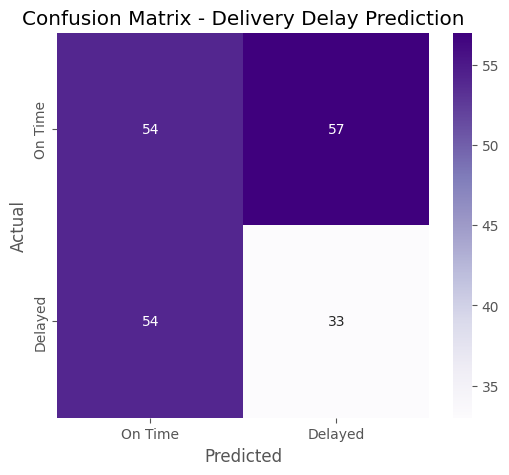

In [96]:
cm = confusion_matrix(y_test, delay_prediction)

plt.figure(figsize=(6,5))

sns.heatmap(

    cm,

    annot=True,

    fmt="d",

    cmap="Purples",

    xticklabels=["On Time","Delayed"],

    yticklabels=["On Time","Delayed"]

)

plt.title("Confusion Matrix - Delivery Delay Prediction")

plt.xlabel("Predicted")

plt.ylabel("Actual")

plt.show()

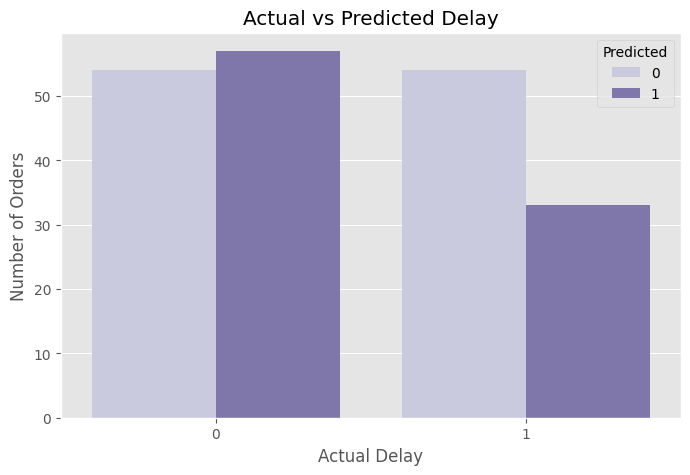

In [ ]:
comparison = pd.DataFrame({

    "Actual": y_test.values,

    "Predicted": delay_prediction

})

comparison_counts = comparison.value_counts().reset_index(name="Count")

plt.figure(figsize=(8,5))

sns.countplot(

    data=comparison,

    x="Actual",

    hue="Predicted",

    palette="Purples"

)

plt.title("Actual vs Predicted Delay")

plt.xlabel("Actual Delay")

plt.ylabel("Number of Orders")

plt.legend(title="Predicted")

plt.show()

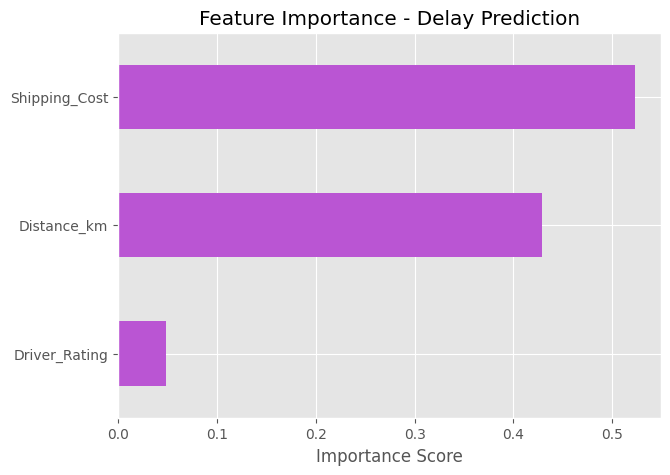

In [ ]:
importance = pd.Series(

    delay_model.feature_importances_,

    index=features

)

importance.sort_values().plot(

    kind="barh",

    figsize=(7,5),

    color="mediumorchid"

)

plt.title("Feature Importance - Delay Prediction")

plt.xlabel("Importance Score")

plt.show()

/tmp/ipykernel_2708/580692081.py:3: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.countplot(


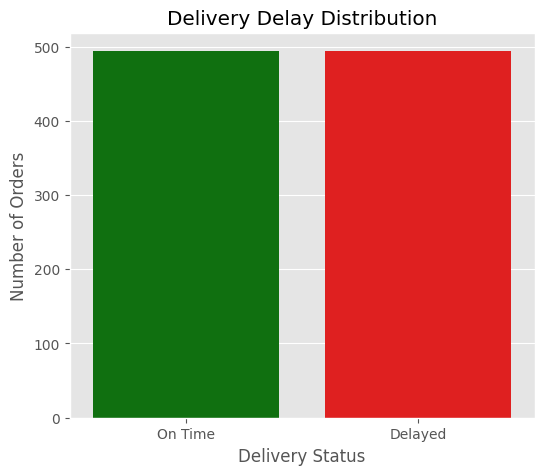

In [97]:
plt.figure(figsize=(6,5))

sns.countplot(

    x=df["Delay"],

    palette=["green","red"]

)

plt.xticks(

    [0,1],

    ["On Time","Delayed"]

)

plt.title("Delivery Delay Distribution")

plt.xlabel("Delivery Status")

plt.ylabel("Number of Orders")

plt.show()

##  ETA Prediction

In [54]:
from sklearn.model_selection import train_test_split
from sklearn.ensemble import RandomForestRegressor

from sklearn.metrics import mean_absolute_error
from sklearn.metrics import mean_squared_error
from sklearn.metrics import r2_score

In [55]:
features = [
    "Distance_km",
    "Shipping_Cost",
    "Driver_Rating"
]

X = df[features]
y = df["Delivery_Time"]

In [56]:
X_train, X_test, y_train, y_test = train_test_split(
    X,
    y,
    test_size=0.2,
    random_state=42
)

In [57]:
eta_model = RandomForestRegressor(
    n_estimators=100,
    random_state=42
)

eta_model.fit(X_train, y_train)

RandomForestRegressor(random_state=42)

In [58]:
eta_prediction = eta_model.predict(X_test)

In [59]:
print("MAE :", mean_absolute_error(y_test, eta_prediction))

print("RMSE :", mean_squared_error(y_test, eta_prediction)**0.5)

print("R2 Score :", r2_score(y_test, eta_prediction))

MAE : 2.8142555555555546
RMSE : 3.314654297939452
R2 Score : -0.11030133207253123


In [60]:
comparison = pd.DataFrame({

    "Actual ETA": y_test.values,

    "Predicted ETA": eta_prediction

})

comparison.head(10)

,Actual ETA,Predicted ETA
0,3.82,4.9057
1,7.57,5.1009
2,4.96,5.3488
3,9.63,8.9205
4,5.97,6.1118
5,1.95,7.9633
6,1.06,6.9588
7,11.72,7.5752
8,11.31,5.7761
9,2.07,7.2507


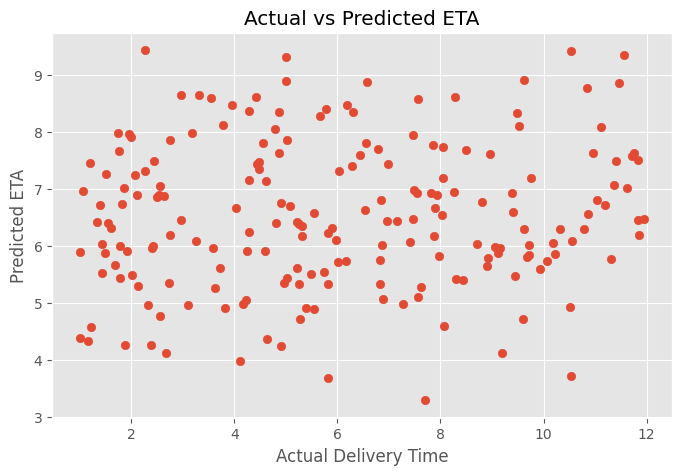

In [61]:
plt.figure(figsize=(8,5))

plt.scatter(y_test,
            eta_prediction)

plt.xlabel("Actual Delivery Time")

plt.ylabel("Predicted ETA")

plt.title("Actual vs Predicted ETA")

plt.show()

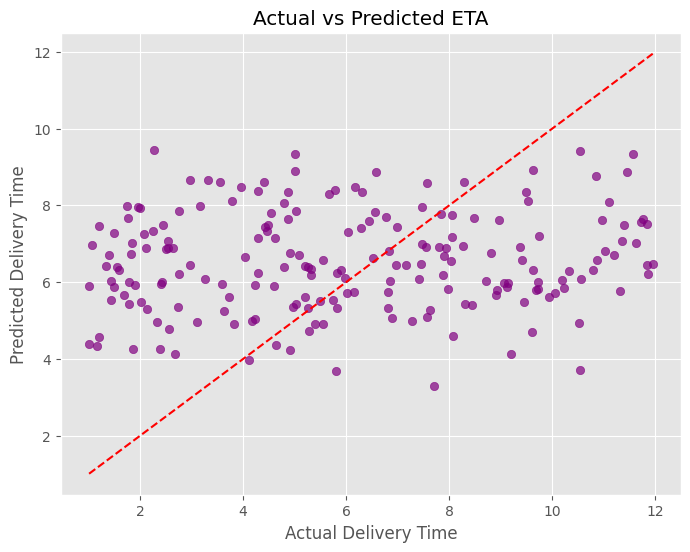

In [62]:
plt.figure(figsize=(8,6))

plt.scatter(y_test, eta_prediction, color="purple", alpha=0.7)

plt.plot(
    [y_test.min(), y_test.max()],
    [y_test.min(), y_test.max()],
    color="red",
    linestyle="--"
)

plt.title("Actual vs Predicted ETA")
plt.xlabel("Actual Delivery Time")
plt.ylabel("Predicted Delivery Time")

plt.show()

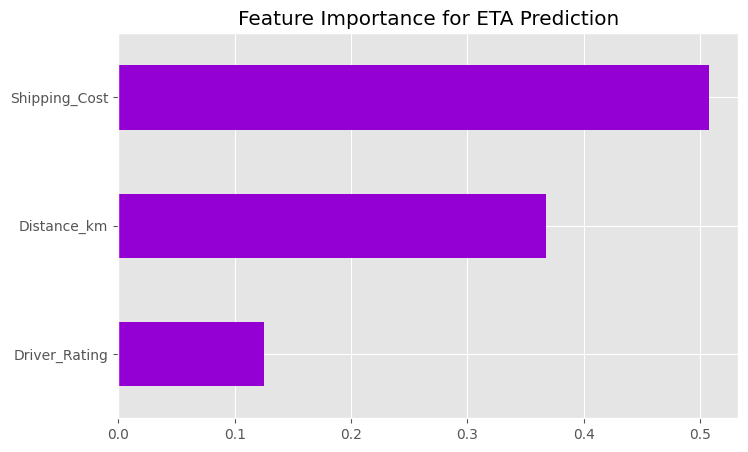

In [71]:
importance = pd.Series(
    eta_model.feature_importances_,
    index=features
)

importance.sort_values().plot(
    kind="barh",
    figsize=(8,5),
    color="darkviolet"
)

plt.title("Feature Importance for ETA Prediction")

plt.show()

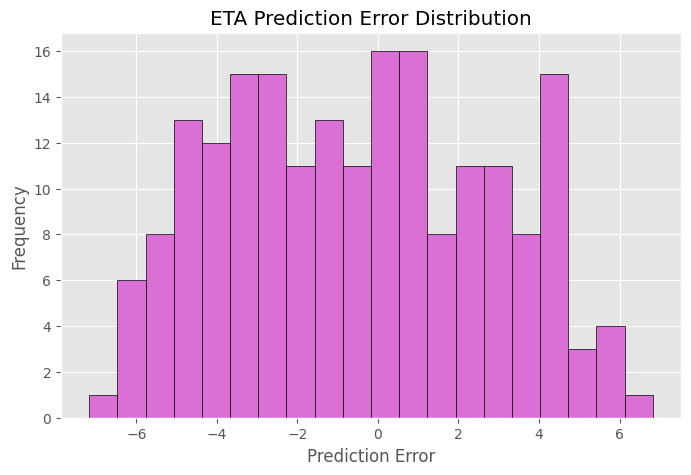

In [72]:
errors = y_test - eta_prediction

plt.figure(figsize=(8,5))

plt.hist(
    errors,
    bins=20,
    color="orchid",
    edgecolor="black"
)

plt.title("ETA Prediction Error Distribution")
plt.xlabel("Prediction Error")
plt.ylabel("Frequency")

plt.show()

## Fleet Performance Monitoring

In [63]:
print("Fleet Performance Summary")
print()

print("Total Orders :", len(df))

print("Average Driver Rating :", round(df["Driver_Rating"].mean(),2))

print("Average Delivery Time :", round(df["Delivery_Time"].mean(),2))

print("Average Shipping Cost :", round(df["Shipping_Cost"].mean(),2))

print("Average Distance :", round(df["Distance_km"].mean(),2))

Fleet Performance Summary

Total Orders : 988
Average Driver Rating : 3.05
Average Delivery Time : 6.52
Average Shipping Cost : 821.8
Average Distance : 53.51


In [64]:
fleet = df.groupby("Vehicle_Type")[

    ["Delivery_Time",

     "Shipping_Cost",

     "Driver_Rating"]

].mean()

fleet

,Delivery_Time,Shipping_Cost,Driver_Rating
Vehicle_Type,,,
Bike,6.514583,865.047619,3.127976
Truck,6.520819,791.947368,2.938596
Van,6.510710,807.864516,3.074194


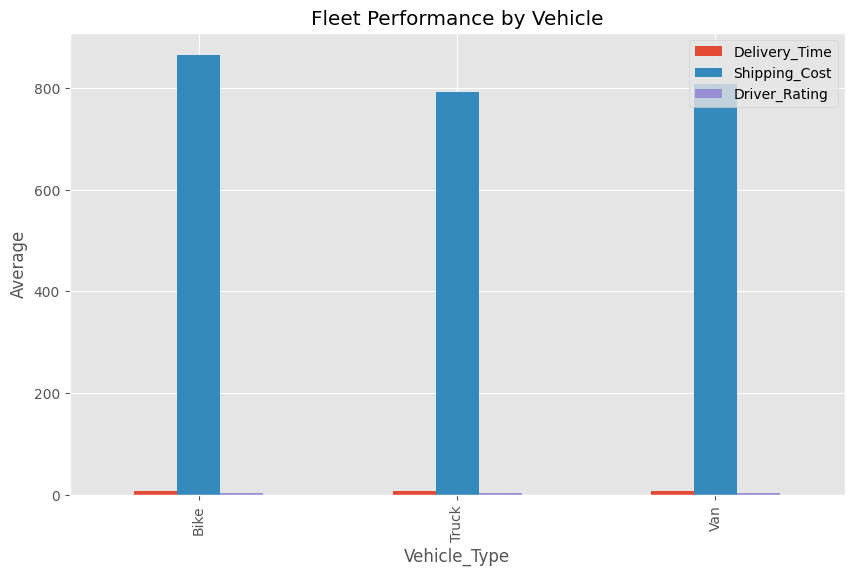

In [65]:
 fleet.plot(kind="bar",

figsize=(10,6))

plt.title("Fleet Performance by Vehicle")

plt.ylabel("Average")

plt.show()

#AI Insights

In [66]:
print("AI Insights")
print()

print("Highest Shipping Cost Vehicle :")

print(df.groupby("Vehicle_Type")["Shipping_Cost"].mean().idxmax())

print()

print("Highest Delivery Time Weather :")

print(df.groupby("Weather")["Delivery_Time"].mean().idxmax())

print()

print("Highest Traffic Delay :")

print(df.groupby("Traffic")["Delivery_Time"].mean().idxmax())

AI Insights

Highest Shipping Cost Vehicle :
Bike

Highest Delivery Time Weather :
Rain

Highest Traffic Delay :
Low


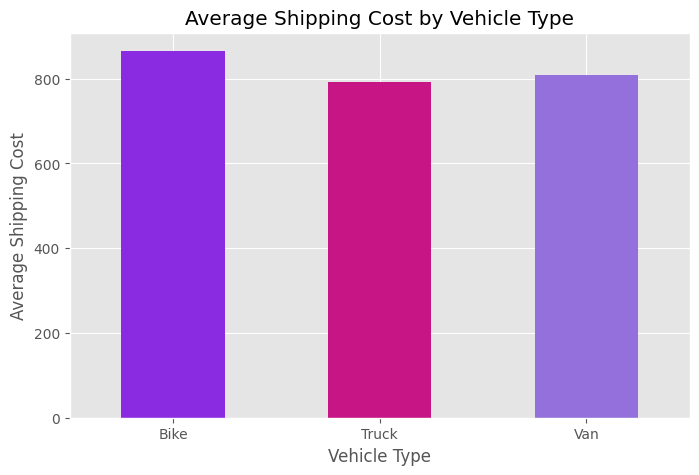

In [67]:
plt.figure(figsize=(8,5))

shipping = df.groupby("Vehicle_Type")["Shipping_Cost"].mean()

shipping.plot(kind="bar", color=["#8A2BE2", "#C71585", "#9370DB"])

plt.title("Average Shipping Cost by Vehicle Type")
plt.xlabel("Vehicle Type")
plt.ylabel("Average Shipping Cost")

plt.xticks(rotation=0)

plt.show()

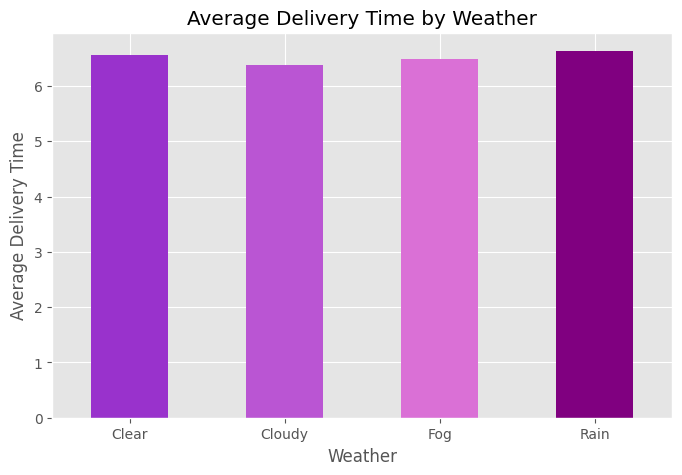

In [68]:
plt.figure(figsize=(8,5))

weather = df.groupby("Weather")["Delivery_Time"].mean()

weather.plot(kind="bar", color=["#9932CC","#BA55D3","#DA70D6","#800080"])

plt.title("Average Delivery Time by Weather")
plt.xlabel("Weather")
plt.ylabel("Average Delivery Time")

plt.xticks(rotation=0)

plt.show()

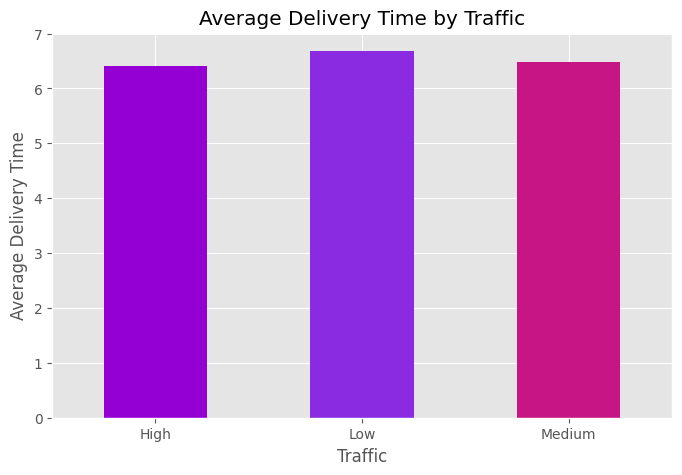

In [69]:
plt.figure(figsize=(8,5))

traffic = df.groupby("Traffic")["Delivery_Time"].mean()

traffic.plot(kind="bar", color=["#9400D3","#8A2BE2","#C71585"])

plt.title("Average Delivery Time by Traffic")
plt.xlabel("Traffic")
plt.ylabel("Average Delivery Time")

plt.xticks(rotation=0)

plt.show()

##  Operational Alerts

In [73]:
delay_rate = (df["Delay"].sum()/len(df))*100

print("Delay Percentage :", round(delay_rate,2),"%")

if delay_rate>25:

    print("🔴 ALERT : High Delivery Delay")

else:

    print("🟢 Delivery Performance Normal")

Delay Percentage : 25.81 %
🔴 ALERT : High Delivery Delay


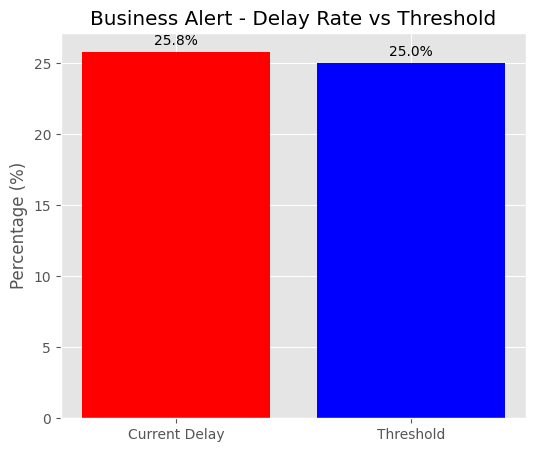

In [74]:
delay_percentage = delay_rate
threshold = 25

plt.figure(figsize=(6,5))

plt.bar(
    ["Current Delay", "Threshold"],
    [delay_percentage, threshold],
    color=["red", "blue"]
)

plt.title("Business Alert - Delay Rate vs Threshold")
plt.ylabel("Percentage (%)")

for i, value in enumerate([delay_percentage, threshold]):
    plt.text(i, value + 0.5, f"{value:.1f}%", ha="center")

plt.show()

In [99]:
df.to_csv("Final_AI_Logistics_Dataset.csv", index=False)

print("Final Dataset Saved Successfully")

Final Dataset Saved Successfully
